# Chapter 70: Fiscal Federalism, Local Public Finance, and Tiebout Sorting

This notebook reruns four worked examples from the chapter: tailored versus uniform local service, Tiebout sorting between two towns, tax capitalization into house prices, and Wagner's law. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def annuity_factor(r, n):
    """Present value of 1 per period for n periods: (1 - (1 + r)^-n) / r (n when r = 0)."""
    return float(n) if r == 0 else (1.0 - (1.0 + r) ** (-n)) / r


def annuity_pv(payment, r, n):
    """payment x annuity_factor(r, n)."""
    return payment * annuity_factor(r, n)


def perpetuity_pv(payment, r):
    """payment / r."""
    return payment / r


def decentralization_gain(peaks, uniform_q=None, top=49.0):
    """Districts with surplus top - (q - peak)^2: tailored choice q = peak against one uniform q.

    Principle: oates-decentralization-theorem. The best uniform q is the mean peak. Book (ch070):
    peaks (1, 4, 7) give W^D = 147, q^U = 4, surpluses 40, 49, 40, W^U = 129, gain 18.
    """
    if uniform_q is None:
        uniform_q = sum(peaks) / len(peaks)
    uniform = [top - (uniform_q - pk) ** 2 for pk in peaks]
    wd = top * len(peaks)
    return {"W_D": wd, "q_U": uniform_q, "uniform": uniform, "W_U": sum(uniform), "gain": wd - sum(uniform)}


def spillover_optimum(peak, s, top=49.0):
    """Social contribution S(q) + s q of a district whose service spills s per unit onto a neighbour.

    Principle: oates-decentralization-theorem. Optimum q = peak + s/2. Book (ch070): peak 1, s = 2 gives
    51 at the local choice q = 1 and 52 at q = 2.
    """
    def contribution(q):
        return top - (q - peak) ** 2 + s * q

    q_opt = peak + s / 2
    return {"q_local": peak, "q_opt": q_opt, "local": contribution(peak), "optimum": contribution(q_opt),
            "loss": contribution(q_opt) - contribution(peak), "contribution": contribution}


def tiebout_payoffs(values=(12.0, 4.0), harbor_tax=5.0, plain_service=3.0, plain_tax=2.0, m=0.0, rent=0.0):
    """Two towns: Harbor (package valued by type, tax, rent premium) and Plain (basic service, tax).

    Principle: tiebout-sorting. Book (ch070): high 12 - 5 = 7 in Harbor, 3 - 2 = 1 in Plain; low 4 - 5 = -1
    and 1; relocation gain for a high type in Plain (12 - 5) - (3 - 2) - m = 6 - m; rent 4 gives 7 - 4 = 3.
    The move gain here also subtracts any rent premium.
    """
    high, low = values
    plain = plain_service - plain_tax
    h_h, l_h = high - harbor_tax - rent, low - harbor_tax - rent
    fiscal_adv = (high - harbor_tax) - plain
    gain = fiscal_adv - rent - m
    return {"high_harbor": h_h, "high_plain": plain, "low_harbor": l_h, "low_plain": plain,
            "fiscal_advantage": fiscal_adv, "move_gain": gain, "moves": gain > 0}


def wagner_projection(G0, Y0, Y1, eps):
    """G1 = G0 (Y1/Y0)^eps with the share and growth rates.

    Principle: wagners-law. Book (ch070): G0 = 96, Y0 = 800, Y1 = 1,200, eps 1.25 gives 159.36, share 0.1328,
    spending growth about 66 percent; eps 0.75 gives 130.12 and share 0.1084.
    """
    G1 = G0 * (Y1 / Y0) ** eps
    return {"G1": G1, "share0": G0 / Y0, "share1": G1 / Y1, "g_growth": G1 / G0 - 1, "y_growth": Y1 / Y0 - 1}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(annuity_factor=annuity_factor, annuity_pv=annuity_pv, perpetuity_pv=perpetuity_pv)


public = SimpleNamespace(decentralization_gain=decentralization_gain, spillover_optimum=spillover_optimum, tiebout_payoffs=tiebout_payoffs, wagner_projection=wagner_projection)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'oates-decentralization-theorem': {'peaks': (1, 4, 7),
                                    'top': 49,
                                    'W_D': 147,
                                    'q_U': 4,
                                    'uniform': (40, 49, 40),
                                    'W_U': 129,
                                    'gain': 18,
                                    'spill': 2,
                                    'q_opt': 2,
                                    'local': 51,
                                    'optimum': 52},
 'tiebout-sorting': {'high': 12,
                     'low': 4,
                     'harbor_tax': 5,
                     'plain_service': 3,
                     'plain_tax': 2,
                     'high_harbor': 7,
                     'high_plain': 1,
                     'low_harbor': -1,
                     'low_plain': 1,
                     'high_loss': 6,
                     'low_loss': 2,
                     'm_blocked': 7,
                     'rent': 4,
                     'high_harbor_rent': 3},
 'oates-capitalization-effect': {'price': 360000,
                                 'tax': 2400,
                                 'service': 1500,
                                 'r': 0.045,
                                 'df': -900,
                                 'dP': -20000,
                                 'new_price': 340000,
                                 'years': 10,
                                 'dP_10': -7121,
                                 'service_high': 2800,
                                 'df_high': 400,
                                 'dP_high': 8889,
                                 'new_price_high': 368889},
 'wagners-law': {'Y0': 800,
                 'G0': 96,
                 'share0': 0.12,
                 'Y1': 1200,
                 'eps': 1.25,
                 'G1': 159.36,
                 'share1': 0.1328,
                 'g_growth': 0.66,
                 'y_growth': 0.5,
                 'eps_low': 0.75,
                 'G1_low': 130.12,
                 'share1_low': 0.1084},
 'constructed': {'oates-decentralization-theorem': {'spread': [0, 1], 'spill': [0, 4]},
                 'tiebout-sorting': {'m': [4], 'rent': [8]},
                 'oates-capitalization-effect': {'service': [2400], 'years': [20]},
                 'wagners-law': {'eps': [1.0, 1.5], 'Y1': [1000, 1600]}}}


def oates_picture(spread=3, spill=2):
    peaks = (4 - spread, 4, 4 + spread)
    d = public.decentralization_gain(peaks)
    s = public.spillover_optimum(peaks[0], spill)
    fig, (ax1, ax2) = new_figure(ncols=2)
    q = np.linspace(0, 10, 300)
    cols = ["teal", "navy", "gold"]
    for i, pk in enumerate(peaks):
        ax1.plot(q, 49 - (q - pk) ** 2, color=PALETTE[cols[i]], linewidth=2.0, linestyle="solid" if i != 1 else "dashed")
    ax1.axvline(d["q_U"], color=PALETTE["grey"], linestyle="dotted", linewidth=1.3)
    for i, pk in enumerate(peaks):
        ax1.scatter([pk], [49], color=PALETTE[cols[i]], s=40, zorder=5)
        ax1.scatter([d["q_U"]], [d["uniform"][i]], color=PALETTE["terracotta"], s=30, zorder=6)
    ax1.text(0.03, 0.97, f"peaks at q = {', '.join(num(p, 0) for p in peaks)}", transform=ax1.transAxes,
             ha="left", va="top", fontsize=10.5, color=PALETTE["ink"])
    ax1.text(0.03, 0.89, f"red: surplus at uniform q = {num(d['q_U'], 0)}", transform=ax1.transAxes, ha="left",
             va="top", fontsize=10.5, color=PALETTE["terracotta"])
    ax1.set_xlim(0, 10)
    ax1.set_ylim(0, 62)
    ax1.set_xlabel("Units of service q")
    ax1.set_ylabel("District net surplus S(q)")
    f = s["contribution"]
    ax2.plot(q, [f(x) for x in q], color=PALETTE["teal"], linewidth=2.2)
    mark(ax2, s["q_local"], s["local"], f"local q = {num(s['q_local'], 0)}: {num(s['local'], 0)}", col="terracotta",
         dx=8, dy=-14, va="top")
    if s["q_opt"] != s["q_local"]:
        mark(ax2, s["q_opt"], s["optimum"], f"best q = {num(s['q_opt'], 0)}: {num(s['optimum'], 0)}", col="navy",
             dx=8, dy=8)
    ys = [f(x) for x in q]
    ax2.set_ylim(min(ys) - 5, max(ys) + 14)
    ax2.set_xlim(0, 10)
    ax2.set_xlabel("District 1 service q_1")
    ax2.set_ylabel(f"S_1(q) + {num(spill, 0)}q")
    outer = d["uniform"][0]
    metrics = {"Tailored welfare W^D": num(d["W_D"], 0), "Uniform welfare W^U": num(d["W_U"], 0),
               "Tailoring gain": num(d["gain"], 0), "District 1 contribution at local choice": num(s["local"], 0),
               "Best q for District 1": num(s["q_opt"], 0), "Contribution at best q": num(s["optimum"], 0)}
    steps = ["W^D = 49 + 49 + 49 = 147",
             f"Uniform q^U = {num(d['q_U'], 0)}: outer districts get 49 - {spread}^2 = {num(outer, 0)}",
             f"W^U = {num(outer, 0)} + 49 + {num(outer, 0)} = {num(d['W_U'], 0)}; gain = 147 - {num(d['W_U'], 0)} = "
             f"{num(d['gain'], 0)}",
             f"Spillover: -2(q - {peaks[0]}) + {spill} = 0 gives q = {num(s['q_opt'], 0)}",
             f"At q = {peaks[0]}: 49 + {spill} x {peaks[0]} = {num(s['local'], 0)}; at q = {num(s['q_opt'], 0)}: "
             f"49 - {num(spill / 2, 0)}^2 + {spill} x {num(s['q_opt'], 0)} = {num(s['optimum'], 0)}"]
    if d["gain"] > 0:
        tail = (f"A uniform rule at q = 4 leaves the outer districts {spread} {'unit' if spread == 1 else 'units'} "
                f"from their peaks, so W^U = "
                f"{num(outer, 0)} + 49 + {num(outer, 0)} = {num(d['W_U'], 0)} and tailoring gains "
                f"{num(d['gain'], 0)}.")
    else:
        tail = "With identical peaks the uniform rule gives every district its peak, so tailoring gains nothing."
    if spill > 0:
        sp = (f"With a spillover of {spill} per unit, District 1's social contribution peaks at q = "
              f"{num(s['q_opt'], 0)} ({num(s['optimum'], 0)}) rather than its own choice q = {peaks[0]} "
              f"({num(s['local'], 0)}), so it underprovides by {num(s['q_opt'] - s['q_local'], 0)} "
              f"{'unit' if s['q_opt'] - s['q_local'] == 1 else 'units'}.")
    else:
        sp = "With no spillover District 1's own choice is also socially best."
    interp = f"Tailored choices give each district 49, so W^D = 49 + 49 + 49 = 147. {tail} {sp}"
    alt = (f"Left: three district surplus parabolas peaking at {', '.join(str(p) for p in peaks)}, with the uniform "
           f"quantity 4 marked. Right: District 1's social contribution with spillover {spill}, "
           f"{num(s['local'], 0)} at its local choice and {num(s['optimum'], 0)} at q = {num(s['q_opt'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tiebout_picture(m=0, rent=0):
    r = public.tiebout_payoffs(m=m, rent=rent)
    fig, (ax1, ax2) = new_figure(ncols=2)
    xs = np.array([0, 1])
    w = 0.36
    hv = [r["high_harbor"], r["high_plain"]]
    lv = [r["low_harbor"], r["low_plain"]]
    ax1.bar(xs - w / 2, hv, width=w, color=PALETTE["teal"])
    ax1.bar(xs + w / 2, lv, width=w, color=PALETTE["gold"])
    for x, v in list(zip(xs - w / 2, hv)) + list(zip(xs + w / 2, lv)):
        ax1.annotate(num(v, 0), (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                     va="bottom" if v >= 0 else "top", fontsize=10.5, color=PALETTE["ink"])
    ax1.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax1.set_xticks(xs, ["Harbor", "Plain"])
    ax1.set_ylim(-11, 12)
    ax1.text(0.97, 0.97, "teal: high value (12)", transform=ax1.transAxes, ha="right", va="top", fontsize=10.5,
             color=PALETTE["teal"])
    ax1.text(0.97, 0.89, "gold: low value (4)", transform=ax1.transAxes, ha="right", va="top", fontsize=10.5,
             color=PALETTE["gold"])
    ax1.set_xlabel("Town")
    ax1.set_ylabel("Net fiscal payoff")
    names = ["Fiscal gap", "Rent", "Moving cost", "Net gain"]
    vals = [r["fiscal_advantage"], -rent, -m, r["move_gain"]]
    bar_compare(ax2, names, vals, colors=["teal", "terracotta", "terracotta", "navy" if r["moves"] else "grey"],
                value_labels=[num(v, 0) for v in vals], ylabel="Gain from moving Plain to Harbor", xlabel="Component")
    ax2.set_ylim(-17, 10)
    gain = r["move_gain"]
    verdict = ("moves to Harbor" if gain > 0 else ("is indifferent" if gain == 0 else "stays in Plain"))
    hh = r["high_harbor"]
    pref = ("prefers Harbor" if hh > 1 else ("is indifferent between the towns" if hh == 1 else "prefers Plain"))
    metrics = {"High type in Harbor": num(hh, 0), "High type in Plain": "1", "Low type in Harbor": num(r["low_harbor"], 0),
               "Low type in Plain": "1", "Gain from moving": num(gain, 0),
               "Move happens": "Yes" if gain > 0 else "No"}
    rent_part = f" - {rent}" if rent else ""
    steps = [f"High in Harbor: 12 - 5{rent_part} = {num(hh, 0)}; in Plain: 3 - 2 = 1",
             f"Low in Harbor: 4 - 5{rent_part} = {num(r['low_harbor'], 0)}; in Plain: 1",
             f"Gain from moving: (12 - 5) - (3 - 2){rent_part} - {m} = {num(gain, 0)}",
             f"The move happens only if the gain is positive: {num(gain, 0)} means the household {verdict}"]
    interp = (f"A high-value household nets 12 - 5{rent_part} = {num(hh, 0)} in Harbor against 3 - 2 = 1 in Plain, "
              f"so it {pref}. A low-value household nets {num(r['low_harbor'], 0)} in Harbor and 1 in Plain, so it "
              f"prefers Plain. For a high-value household now in Plain the gain from moving is 7 - 1{rent_part} - {m} "
              f"= {num(gain, 0)}, so it {verdict}.")
    if rent:
        interp += f" The rent premium of {rent} goes to Harbor's property owners, not to the town's budget."
    alt = (f"Left: net payoffs, high type {num(hh, 0)} in Harbor and 1 in Plain, low type {num(r['low_harbor'], 0)} "
           f"and 1. Right: the move decision, fiscal gap 6 less rent {rent} and moving cost {m} gives {num(gain, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def capitalization_picture(service=1500, duration="perpetual"):
    b = BV["oates-capitalization-effect"]
    r, tax, base = b["r"], b["tax"], b["price"]
    df = service - tax
    if duration == "perpetual":
        dP = choice.perpetuity_pv(df, r)
        how = f"{num(df, 0)} / 0.045"
    else:
        n = int(duration)
        fac = choice.annuity_factor(r, n)
        dP = choice.annuity_pv(df, r, n)
        how = f"{num(df, 0)} x (1 - 1.045^-{n}) / 0.045 = {num(df, 0)} x {num(fac, 4)}"
    fig, (ax1, ax2) = new_figure(ncols=2)
    ns = np.arange(1, 51)
    ax1.plot(ns, [choice.annuity_pv(df, r, int(k)) / 1000 for k in ns], color=PALETTE["teal"], linewidth=2.2)
    hline(ax1, choice.perpetuity_pv(df, r) / 1000, f"perpetual: {num(choice.perpetuity_pv(df, r) / 1000, 2)}k",
          col="grey", x_frac=0.35, va="bottom" if df >= 0 else "top")
    xn = 50 if duration == "perpetual" else int(duration)
    mark(ax1, xn, dP / 1000, None, col="terracotta")
    ax1.set_xlim(0, 52)
    ax1.set_ylim(-23, 12)
    ax1.set_xlabel("Expected years the change lasts")
    ax1.set_ylabel("Capitalized price change ($ thousand)")
    bar_compare(ax2, ["Comparison house", "Affected house"], [base / 1000, (base + dP) / 1000],
                colors=["grey", "terracotta" if dP < 0 else "teal"],
                value_labels=[tex_safe(money(base, 0)), tex_safe(money(base + dP, 0))], ylabel="Price ($ thousand)",
                xlabel="House")
    ax2.set_ylim(300, 395)
    metrics = {"Annual net fiscal change": money(df, 0), "Capitalized price change": money(dP, 0),
               "Affected house price": money(base + dP, 0)}
    dur = "a perpetual change" if duration == "perpetual" else f"{duration} years"
    steps = [f"Delta f = {num(service, 0)} - 2,400 = {num(df, 0)}",
             f"Delta P = {how} = {num(dP, 0)}",
             f"Price = 360,000 + {signed(dP, 0)} = {num(base + dP, 0)}"]
    if df == 0:
        sign = "Service value exactly offsets the tax, so nothing is capitalized and the price is unchanged."
    elif df < 0:
        sign = "The tax outweighs the service, so the owner at the time of the surprise absorbs the loss."
    else:
        sign = "The service is worth more than the tax, so the house gains value."
    interp = (f"Net fiscal value changes by {num(service, 0)} - 2,400 = {num(df, 0)} a year. Discounted at 4.5 "
              f"percent over {dur}, Delta P = {how} = {money(dP, 0)}, so the affected house sells for "
              f"{money(base + dP, 0)}. {sign}")
    alt = (f"Left: the capitalized price change against how long the {money(df, 0)} annual change lasts, approaching "
           f"the perpetual value. Right: comparison house $360,000 and affected house {money(base + dP, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def wagner_picture(eps=1.25, y1=1200):
    Y1 = y1
    b = BV["wagners-law"]
    G0, Y0 = b["G0"], b["Y0"]
    r = public.wagner_projection(G0, Y0, Y1, eps)
    ratio = Y1 / Y0
    fig, ax = new_figure()
    Y = np.linspace(800, 1600, 200)
    ax.plot(Y, G0 * (Y / Y0) ** eps, color=PALETTE["teal"], linewidth=2.2, label=f"G = 96 (Y/800)^{num(eps, 2)}")
    ax.plot(Y, 0.12 * Y, color=PALETTE["grey"], linewidth=1.5, linestyle="dashed", label="constant share G = 0.12Y")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.legend(loc="upper left", frameon=False)
    mark(ax, Y1, r["G1"], f"G_1 = {num(r['G1'])}", col="terracotta", dx=-8, dy=-12, ha="right", va="top")
    ax.set_xticks([800, 1000, 1200, 1600], ["800", "1,000", "1,200", "1,600"])
    ax.set_yticks([80, 120, 160, 240], ["80", "120", "160", "240"])
    ax.minorticks_off()
    ax.set_ylim(75, 300)
    ax.set_xlabel("Real income Y (log scale)")
    ax.set_ylabel("Public spending G (log scale)")
    f = ratio ** eps
    s0, s1 = r["share0"], r["share1"]
    if abs(s1 - s0) < 1e-12:
        form = "the share is unchanged, so spending rises with income but the strong form fails"
        short = "Unchanged"
    elif s1 > s0:
        form = "the share rises, matching the strong form"
        short = "Rises"
    else:
        form = "spending rises in level but its share falls, so the strong form fails"
        short = "Falls"
    metrics = {"Later spending G_1": num(r["G1"]), "Share G_1/Y_1": pct(s1, 2), "Spending growth": pct(r["g_growth"], 1),
               "Income growth": pct(r["y_growth"], 1), "Share versus 12%": short}
    steps = [f"Y_1 / Y_0 = {num(Y1, 0)} / 800 = {num(ratio, 4)}",
             f"G_1 = 96 x {num(ratio, 4)}^{num(eps, 2)} = 96 x {num(f, 6)} = {num(r['G1'])}",
             f"Share = {num(r['G1'], 4)} / {num(Y1, 0)} = {num(s1, 4)}",
             f"Spending growth {pct(r['g_growth'], 1)} against income growth {pct(r['y_growth'], 1)}"]
    interp = (f"G_1 = 96 x {num(ratio, 4)}^{num(eps, 2)} = 96 x {num(f, 6)} = {num(r['G1'])}, a share of "
              f"{pct(s1, 2)} against 12% at the start: {form}. Spending grows {pct(r['g_growth'], 1)} while "
              f"income grows {pct(r['y_growth'], 1)}.")
    alt = (f"Log-log plot of spending against income with elasticity {num(eps, 2)} and the constant-share line. At "
           f"income {num(Y1, 0)} spending is {num(r['G1'])}, a share of {pct(s1, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Oates decentralization theorem: tailored versus uniform service

Three districts have surplus $S_i(q)=49-(q-\text{peak})^2$ with peaks 1, 4 and 7.

$$W^D=49+49+49=147, \qquad W^U=40+49+40=129$$

so tailoring gains 18.

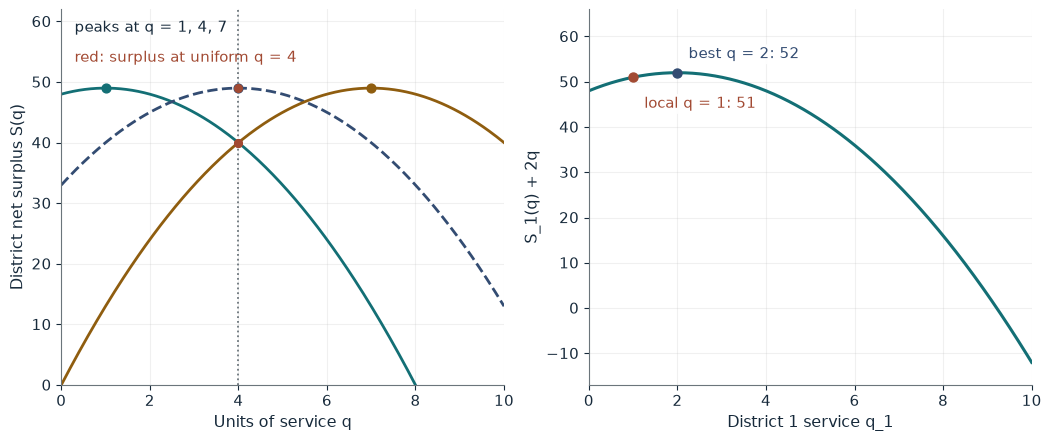

Tailored welfare W^D                     147
Uniform welfare W^U                      129
Tailoring gain                           18
District 1 contribution at local choice  51
Best q for District 1                    2
Contribution at best q                   52

Worked steps:
  1. W^D = 49 + 49 + 49 = 147
  2. Uniform q^U = 4: outer districts get 49 - 3^2 = 40
  3. W^U = 40 + 49 + 40 = 129; gain = 147 - 129 = 18
  4. Spillover: -2(q - 1) + 2 = 0 gives q = 2
  5. At q = 1: 49 + 2 x 1 = 51; at q = 2: 49 - 1^2 + 2 x 2 = 52

Tailored choices give each district 49, so W^D = 49 + 49 + 49 = 147. A uniform rule at q = 4 leaves the outer districts 3 units from their peaks, so W^U = 40 + 49 + 40 = 129 and tailoring gains 18. With a spillover of 2 per unit, District 1's social contribution peaks at q = 2 (52) rather than its own choice q = 1 (51), so it underprovides by 1 unit.


In [2]:
show(oates_picture(spread=3, spill=2))

Change one input, `spread`, and hold the others at the book's values:

In [3]:
sweep(oates_picture, 'spread', [0, 1, 3], {'spill': 2}, ['Uniform welfare W^U', 'Tailoring gain'])

spread | Uniform welfare W^U | Tailoring gain
0 | 147 | 0
1 | 145 | 2
3 | 129 | 18


The gain grows with the square of the distance between peaks. A spillover of 2 per unit moves District 1's social optimum from 1 to 2, raising its contribution from 51 to 52.

## 2. Tiebout sorting: voting with your feet

Harbor charges 5 for a package worth 12 or 4; Plain charges 2 for a service worth 3.

$$(12-5)-(3-2)-m=6-m$$

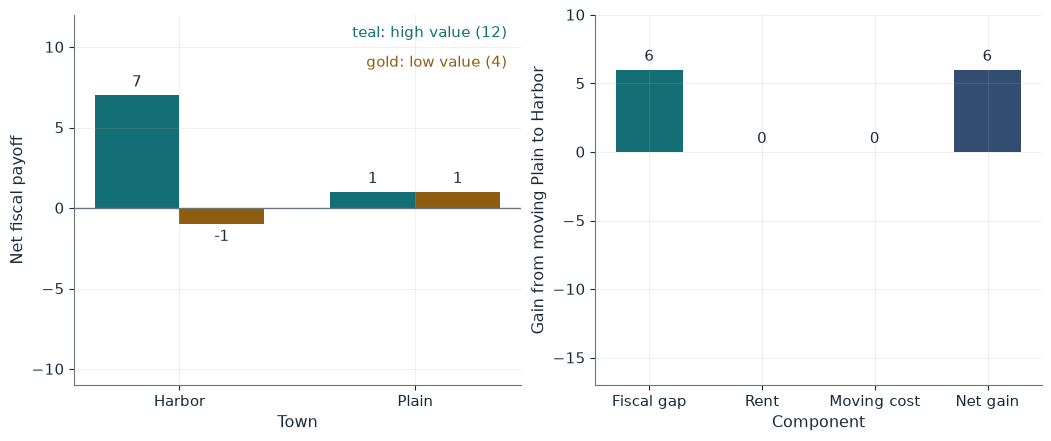

High type in Harbor  7
High type in Plain   1
Low type in Harbor   -1
Low type in Plain    1
Gain from moving     6
Move happens         Yes

Worked steps:
  1. High in Harbor: 12 - 5 = 7; in Plain: 3 - 2 = 1
  2. Low in Harbor: 4 - 5 = -1; in Plain: 1
  3. Gain from moving: (12 - 5) - (3 - 2) - 0 = 6
  4. The move happens only if the gain is positive: 6 means the household moves to Harbor

A high-value household nets 12 - 5 = 7 in Harbor against 3 - 2 = 1 in Plain, so it prefers Harbor. A low-value household nets -1 in Harbor and 1 in Plain, so it prefers Plain. For a high-value household now in Plain the gain from moving is 7 - 1 - 0 = 6, so it moves to Harbor.


In [4]:
show(tiebout_picture(m=0, rent=0))

Change one input, `m`, and hold the others at the book's values:

In [5]:
sweep(tiebout_picture, 'm', [0, 4, 7], {'rent': 0}, ['Gain from moving', 'Move happens'])

m | Gain from moving | Move happens
0 | 6 | Yes
4 | 2 | Yes
7 | -1 | No


High-value households sort into Harbor (7 against 1) and low-value ones into Plain (1 against -1). A moving cost of 7 blocks the move; a rent premium of 4 leaves the high type 7 - 4 = 3, still above 1.

## 3. Oates capitalization effect: taxes and services priced into houses

A \$2,400 tax buys services worth \$1,500 a year, discounted at 4.5 percent.

$$\Delta f=1{,}500-2{,}400=-900, \qquad \Delta P=\frac{-900}{0.045}=-20{,}000$$

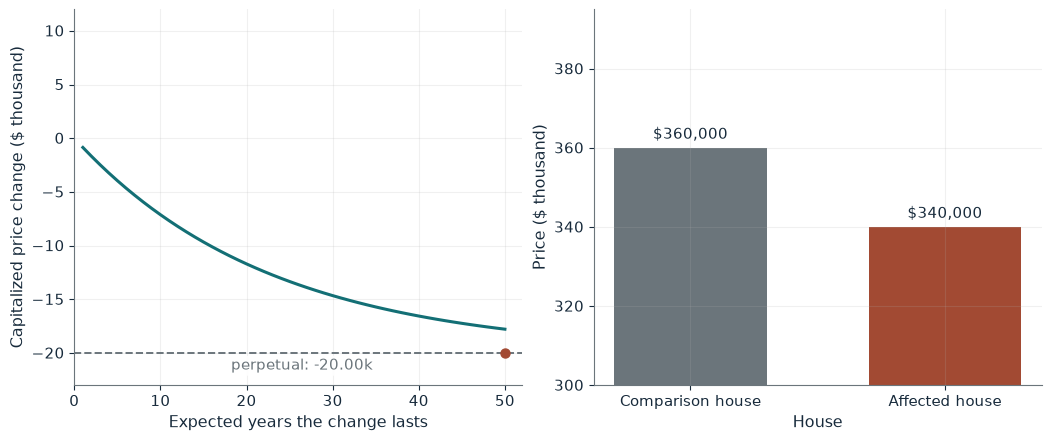

Annual net fiscal change  -$900
Capitalized price change  -$20,000
Affected house price      $340,000

Worked steps:
  1. Delta f = 1,500 - 2,400 = -900
  2. Delta P = -900 / 0.045 = -20,000
  3. Price = 360,000 + (-20,000) = 340,000

Net fiscal value changes by 1,500 - 2,400 = -900 a year. Discounted at 4.5 percent over a perpetual change, Delta P = -900 / 0.045 = -$20,000, so the affected house sells for $340,000. The tax outweighs the service, so the owner at the time of the surprise absorbs the loss.


In [6]:
show(capitalization_picture(service=1500, duration='perpetual'))

Change one input, `duration`, and hold the others at the book's values:

In [7]:
sweep(capitalization_picture, 'duration', ['10', '20', 'perpetual'], {'service': 1500}, ['Capitalized price change', 'Affected house price'])

duration | Capitalized price change | Affected house price
10 | -$7,121 | $352,879
20 | -$11,707 | $348,293
perpetual | -$20,000 | $340,000


A perpetual change lowers the price to \$340,000; if buyers expect it to last 10 years the loss is only \$7,121. With services worth \$2,800 the price instead rises by \$8,889.

## 4. Wagner's law: does government grow faster than income?

Income rises from 800 to 1,200 and spending starts at 96.

$$G_1=96\left(\frac{1{,}200}{800}\right)^{1.25}=96(1.5)^{1.25}\approx159.36$$

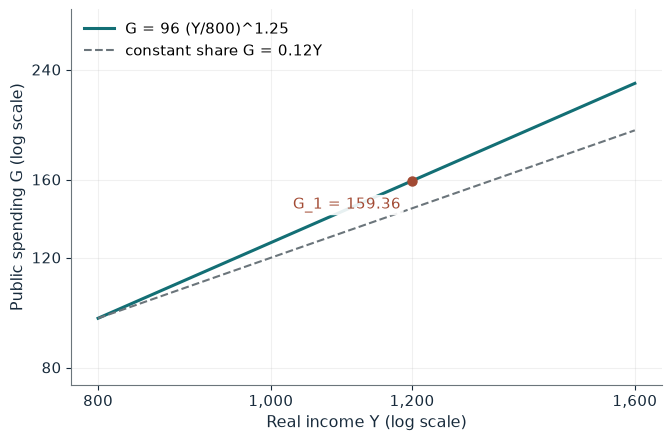

Later spending G_1  159.36
Share G_1/Y_1       13.28%
Spending growth     66.0%
Income growth       50.0%
Share versus 12%    Rises

Worked steps:
  1. Y_1 / Y_0 = 1,200 / 800 = 1.5000
  2. G_1 = 96 x 1.5000^1.25 = 96 x 1.660023 = 159.36
  3. Share = 159.3622 / 1,200 = 0.1328
  4. Spending growth 66.0% against income growth 50.0%

G_1 = 96 x 1.5000^1.25 = 96 x 1.660023 = 159.36, a share of 13.28% against 12% at the start: the share rises, matching the strong form. Spending grows 66.0% while income grows 50.0%.


In [8]:
show(wagner_picture(eps=1.25, y1=1200))

Change one input, `eps`, and hold the others at the book's values:

In [9]:
sweep(wagner_picture, 'eps', [0.75, 1.0, 1.25, 1.5], {'y1': 1200}, ['Later spending G_1', 'Share G_1/Y_1'])

eps | Later spending G_1 | Share G_1/Y_1
0.75 | 130.12 | 10.84%
1.0 | 144.00 | 12.00%
1.25 | 159.36 | 13.28%
1.5 | 176.36 | 14.70%


At elasticity 1.25 the share rises from 12% to 13.28%; at 0.75 spending still rises to 130.12 but the share falls to 10.84%, so rising spending alone does not confirm the strong form.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

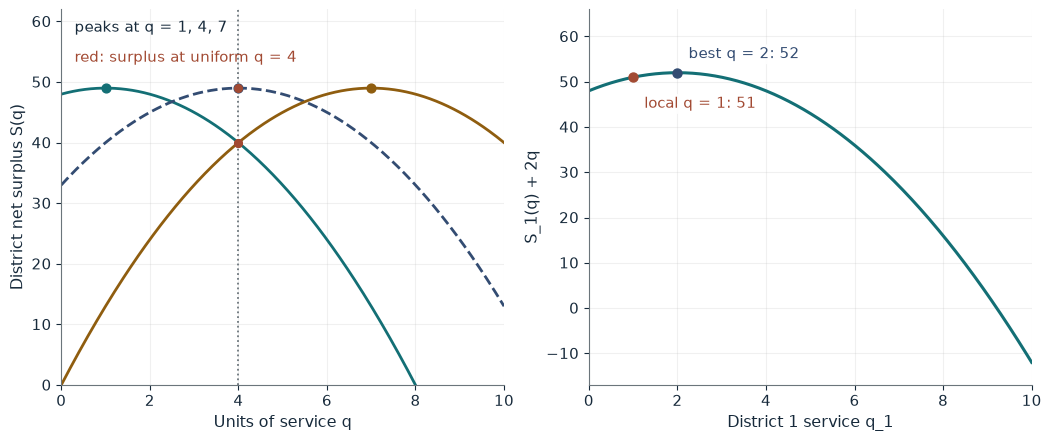

Tailored welfare W^D                     147
Uniform welfare W^U                      129
Tailoring gain                           18
District 1 contribution at local choice  51
Best q for District 1                    2
Contribution at best q                   52

Worked steps:
  1. W^D = 49 + 49 + 49 = 147
  2. Uniform q^U = 4: outer districts get 49 - 3^2 = 40
  3. W^U = 40 + 49 + 40 = 129; gain = 147 - 129 = 18
  4. Spillover: -2(q - 1) + 2 = 0 gives q = 2
  5. At q = 1: 49 + 2 x 1 = 51; at q = 2: 49 - 1^2 + 2 x 2 = 52

Tailored choices give each district 49, so W^D = 49 + 49 + 49 = 147. A uniform rule at q = 4 leaves the outer districts 3 units from their peaks, so W^U = 40 + 49 + 40 = 129 and tailoring gains 18. With a spillover of 2 per unit, District 1's social contribution peaks at q = 2 (52) rather than its own choice q = 1 (51), so it underprovides by 1 unit.


In [10]:
show(oates_picture(spread=3, spill=2))

## Practice

**1.** With peaks 1, 4, 7 and a spillover of 4 per unit, what is District 1's best quantity?

<details><summary>Answer</summary>

-2(q - 1) + 4 = 0 gives q = 3; contribution 57 against 53 at q = 1, a loss of 4.

</details>

**2.** With a rent premium of 8 and no moving cost, where does a high-value household prefer to live?

<details><summary>Answer</summary>

Harbor nets 12 - 5 - 8 = -1, below Plain's 1, so Plain.

</details>

**3.** With a 20-year horizon and service value \$1,500, what is the capitalized change?

<details><summary>Answer</summary>

-900 x 13.0079 = -\$11,707.

</details>